# Generative Adversarial Nets — a small-scale re-implementation
**Paper:** Goodfellow et al., *Generative Adversarial Nets* (NIPS 2014), [arXiv:1406.2661](https://arxiv.org/abs/1406.2661)

This notebook is a from-scratch PyTorch implementation of the GAN framework (minimax and non-saturating generator losses, MLP generator, maxout discriminator with dropout, Parzen-window evaluation) together with a toy 2-D mode-collapse study and a reduced-scale MNIST experiment.

> **Note on the stored outputs.** The outputs saved in this notebook come from the author's original run (Google Colab, T4 GPU, `FAST = False`). In that run the **MNIST GAN collapsed** (Sections 5–6): the Parzen log-likelihood of the main run (−321 for the non-saturating loss) is far below the paper's +225, so this is *not* a successful reproduction of the paper's Table 1. The toy 2-D experiments (Sections 3–4) behave as the paper describes. See the report in `../report/` for the full discussion.

### Notebook map
| Section | What it does |
|---|---|
| 0 | Setup + compute budget (`FAST` flag) |
| 1 | Core code: config, MLP G/D, minimax & non-saturating losses, one training loop used everywhere |
| 2 | Why the two losses differ (gradient saturation) |
| 3 | **Toy 2-D experiments:** 8-Gaussian ring + 5×5 grid, mode-collapse metrics, snapshots, multi-seed table, "Helvetica scenario" |
| 4 | **Toy ablations:** D:G update ratio, capacity, noise dim, batch size, Adam β1, learning rate, depth |
| 5 | **MNIST:** train minimax vs non-saturating, samples, training diagnostics, nearest-training-example check, z-interpolation |
| 6 | **Comparison with the paper's Table 1:** Parzen-window log-likelihood (+ sanity baselines, classifier-based coverage) |
| 7 | **MNIST ablations** (single seed, preliminary) |
| 8 | Deviations from the paper and summary of what the stored outputs show |

### How to run
Run all cells top to bottom. Set `FAST = True` in Section 0 for a quick smoke test (shorter runs, poorer results, same code path). MNIST is downloaded to `./data` on first run. Approximate run times in the stored run (Colab T4, `FAST = False`): toy ablations ≈ 37 min, main MNIST training (two losses) ≈ 4 min, MNIST ablations ≈ 9 min.

## 0. Setup

In [1]:
import math, time, random, warnings
from dataclasses import dataclass, asdict, replace

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display

warnings.filterwarnings("ignore")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device:", device)

def set_seed(seed: int):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})

# ============ COMPUTE BUDGET (edit me) ============
FAST = False          # True => short smoke-test runs (results will be poorer, code path identical)
if FAST:
    TOY_ITERS, TOY_SEEDS, ABL_SEEDS = 1500, 2, 1
    MNIST_ITERS, ABL_MNIST_ITERS = 4000, 2000
else:
    TOY_ITERS, TOY_SEEDS, ABL_SEEDS = 5000, 3, 2
    MNIST_ITERS, ABL_MNIST_ITERS = 20000, 8000
print(dict(TOY_ITERS=TOY_ITERS, TOY_SEEDS=TOY_SEEDS, ABL_SEEDS=ABL_SEEDS,
           MNIST_ITERS=MNIST_ITERS, ABL_MNIST_ITERS=ABL_MNIST_ITERS))

PyTorch 2.11.0+cu130 | device: cuda
{'TOY_ITERS': 5000, 'TOY_SEEDS': 3, 'ABL_SEEDS': 2, 'MNIST_ITERS': 20000, 'ABL_MNIST_ITERS': 8000}


## 1. Core GAN code

The two-player game from the paper:

$$\min_G \max_D \; V(D,G)=\mathbb{E}_{x\sim p_{data}}[\log D(x)] + \mathbb{E}_{z\sim p_z}[\log(1-D(G(z)))]$$

* **D** is trained to maximise $V$ (implemented as binary cross-entropy on logits).
* **G, minimax (saturating):** minimise $\log(1-D(G(z)))$.
* **G, non-saturating** (the paper's §3 practical trick): minimise $-\log D(G(z))$.

Both are written with `softplus` on *logits* so they are numerically stable:
$\log(1-\sigma(a)) = -\mathrm{softplus}(a)$ and $-\log\sigma(a)=\mathrm{softplus}(-a)$.

A single `Cfg` holds every knob (toy and MNIST), so ablations are just `replace(cfg, field=value)`.

In [2]:
@dataclass(frozen=True)
class Cfg:
    # objective / optimisation
    loss: str = "nonsat"        # "minimax" | "nonsat"
    d_steps: int = 1            # k in the paper's Algorithm 1
    g_steps: int = 1
    lr_g: float = 5e-4
    lr_d: float = 5e-4
    beta1: float = 0.5          # Adam beta1 (or SGD momentum if opt="sgd")
    opt: str = "adam"           # "adam" | "sgd"
    batch_size: int = 256
    iters: int = 5000
    seed: int = 0
    # generator
    z_dim: int = 2
    g_hidden: int = 128
    g_layers: int = 3
    # discriminator
    d_hidden: int = 128
    d_layers: int = 3
    d_act: str = "leaky"        # "leaky" | "maxout"
    maxout_k: int = 5
    d_dropout: float = 0.0

class Maxout(nn.Module):
    def __init__(self, d_in, d_out, k=5):
        super().__init__()
        self.d_out, self.k = d_out, k
        self.lin = nn.Linear(d_in, d_out * k)
    def forward(self, x):
        return self.lin(x).view(-1, self.d_out, self.k).max(2)[0]

def build_G(cfg, out_dim, out_act=None):
    layers, d = [], cfg.z_dim
    for _ in range(cfg.g_layers):
        layers += [nn.Linear(d, cfg.g_hidden), nn.ReLU()]
        d = cfg.g_hidden
    layers.append(nn.Linear(d, out_dim))
    if out_act == "sigmoid":
        layers.append(nn.Sigmoid())
    return nn.Sequential(*layers).to(device)

def build_D(cfg, in_dim):
    # returns LOGITS; D(x) = sigmoid(logit)
    layers, d = [], in_dim
    for _ in range(cfg.d_layers):
        if cfg.d_act == "maxout":
            layers.append(Maxout(d, cfg.d_hidden, cfg.maxout_k))
        else:
            layers += [nn.Linear(d, cfg.d_hidden), nn.LeakyReLU(0.2)]
        if cfg.d_dropout > 0:
            layers.append(nn.Dropout(cfg.d_dropout))
        d = cfg.d_hidden
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers).to(device)

def make_opt(params, lr, cfg):
    if cfg.opt == "adam":
        return torch.optim.Adam(params, lr=lr, betas=(cfg.beta1, 0.999))
    if cfg.opt == "sgd":
        return torch.optim.SGD(params, lr=lr, momentum=cfg.beta1)
    raise ValueError(cfg.opt)

# ---------------- losses (operate on logits) ----------------
def d_loss_fn(real_logits, fake_logits):
    # -[ log D(x) + log(1 - D(G(z))) ]
    return F.softplus(-real_logits).mean() + F.softplus(fake_logits).mean()

def g_loss_fn(fake_logits, kind):
    if kind == "minimax":      # minimise  log(1 - D(G(z)))   (saturates when D(G(z)) ~ 0)
        return -F.softplus(fake_logits).mean()
    if kind == "nonsat":       # minimise -log D(G(z))        (strong gradient when D(G(z)) ~ 0)
        return F.softplus(-fake_logits).mean()
    raise ValueError(kind)

# ---------------- one training loop for everything ----------------
def train_gan(cfg, sample_real, data_dim, out_act=None, cb_iters=(), callback=None, log_every=25):
    # sample_real(n) -> tensor [n, data_dim] on `device`.
    # callback(it, G, D) is called at iterations in cb_iters.
    set_seed(cfg.seed)
    G, D = build_G(cfg, data_dim, out_act), build_D(cfg, data_dim)
    optG, optD = make_opt(G.parameters(), cfg.lr_g, cfg), make_opt(D.parameters(), cfg.lr_d, cfg)
    log = {k: [] for k in ("it", "d_loss", "g_loss", "d_real", "d_fake", "g_grad")}
    cb_iters = set(cb_iters)
    for it in range(1, cfg.iters + 1):
        do_log = (it % log_every == 0) or it == 1
        # ---- discriminator: k steps ----
        for _ in range(cfg.d_steps):
            x = sample_real(cfg.batch_size)
            z = torch.randn(cfg.batch_size, cfg.z_dim, device=device)
            with torch.no_grad():
                x_fake = G(z)
            real_logits, fake_logits = D(x), D(x_fake)
            ld = d_loss_fn(real_logits, fake_logits)
            optD.zero_grad(set_to_none=True); ld.backward(); optD.step()
        # ---- generator ----
        for _ in range(cfg.g_steps):
            z = torch.randn(cfg.batch_size, cfg.z_dim, device=device)
            g_logits = D(G(z))
            lg = g_loss_fn(g_logits, cfg.loss)
            optG.zero_grad(set_to_none=True); lg.backward()
            if do_log:   # measure only (max_norm=inf => no clipping)
                gn = torch.nn.utils.clip_grad_norm_(G.parameters(), float("inf")).item()
            optG.step()
        if do_log:
            log["it"].append(it)
            log["d_loss"].append(ld.item()); log["g_loss"].append(lg.item())
            log["d_real"].append(torch.sigmoid(real_logits).mean().item())
            log["d_fake"].append(torch.sigmoid(g_logits).mean().item())
            log["g_grad"].append(gn)
        if callback is not None and it in cb_iters:
            callback(it, G, D)
    return G, D, log

## 2. Why the two losses differ: gradient saturation

The plot below shows the two generator losses and the magnitude of their gradient with respect to the discriminator's logit as a function of $D(G(z))$. The minimax gradient vanishes exactly when $D(G(z))\to 0$, i.e. when the generator is weakest.

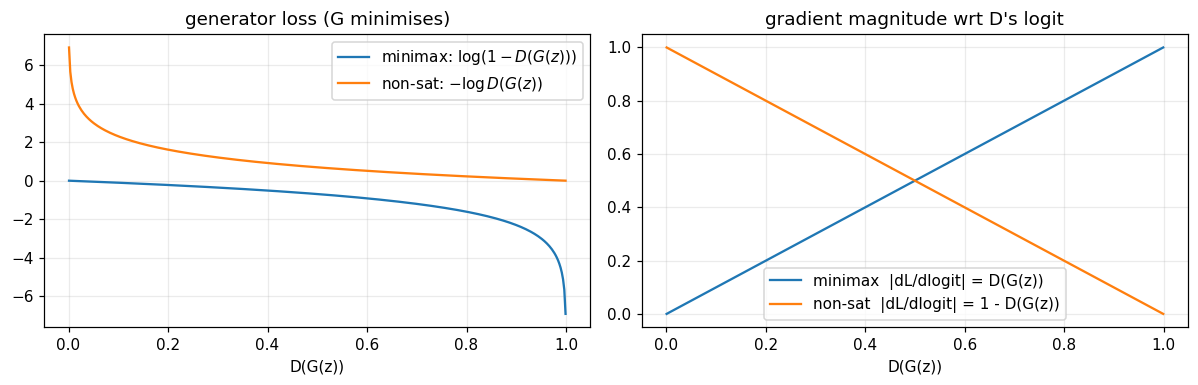

In [3]:
d = np.linspace(1e-3, 1 - 1e-3, 400)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(d, np.log(1 - d), label=r"minimax: $\log(1-D(G(z)))$")
ax[0].plot(d, -np.log(d),   label=r"non-sat: $-\log D(G(z))$")
ax[0].set_xlabel("D(G(z))"); ax[0].set_title("generator loss (G minimises)"); ax[0].legend()
ax[1].plot(d, d,     label="minimax  |dL/dlogit| = D(G(z))")
ax[1].plot(d, 1 - d, label="non-sat  |dL/dlogit| = 1 - D(G(z))")
ax[1].set_xlabel("D(G(z))"); ax[1].set_title("gradient magnitude wrt D's logit"); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Toy 2-D experiments — mode-collapse study

**Datasets** (mixtures of isotropic Gaussians, so we know the true modes exactly):
* `ring8`: 8 modes on a circle of radius 2, σ = 0.05
* `grid25`: 5×5 grid, spacing 2, σ = 0.05 (much harder)

**Metrics** (computed on 5000 generated points):
* **modes covered** — modes that receive at least 10 % of their fair share of *high-quality* samples (a sample is high-quality if it lies within 4σ of its nearest mode).
* **hq** — fraction of generated samples that are high-quality (sample *quality*).
* **js** — Jensen–Shannon divergence (normalised to [0,1]) between the histogram of high-quality samples over modes and the uniform distribution (mode *balance*). 0 = perfectly balanced; 1 = worst.

Mode collapse shows up as low *modes covered* / high *js* while *hq* can still be high (the generator makes sharp samples, but only of a few modes).

In [6]:
class ToyMixture:
    def __init__(self, name, centers, std):
        self.name, self.std = name, std
        self.centers = torch.tensor(np.asarray(centers), dtype=torch.float32, device=device)
        self.K = len(centers)
    def sample(self, n):
        idx = torch.randint(0, self.K, (n,), device=device)
        return self.centers[idx] + self.std * torch.randn(n, 2, device=device)

def ring(k=8, radius=2.0, std=0.05):
    ang = 2 * np.pi * np.arange(k) / k
    return ToyMixture(f"ring{k}", np.stack([radius * np.cos(ang), radius * np.sin(ang)], 1), std)

def grid(n=5, spacing=2.0, std=0.05):
    xs = (np.arange(n) - (n - 1) / 2) * spacing
    return ToyMixture(f"grid{n*n}", np.array([(x, y) for x in xs for y in xs]), std)

@torch.no_grad()
def mode_metrics(samples, ds, hq_k=4.0, cover_frac=0.1):
    dist = torch.cdist(samples, ds.centers)
    dmin, idx = dist.min(1)
    hq = dmin < hq_k * ds.std
    counts = torch.bincount(idx[hq], minlength=ds.K).float()
    N = samples.shape[0]
    modes = int((counts >= cover_frac * N / ds.K).sum().item())
    if counts.sum() == 0:
        js = 1.0
    else:
        p = counts / counts.sum()
        u = torch.full_like(p, 1.0 / ds.K)
        m = 0.5 * (p + u)
        def kl(a, b):
            mask = a > 0
            return (a[mask] * (a[mask] / b[mask]).log()).sum()
        js = (0.5 * kl(p, m) + 0.5 * kl(u, m)).item() / math.log(2)
    return {"modes": modes, "hq": hq.float().mean().item(), "js": js}

@torch.no_grad()
def toy_eval(G, ds, cfg, n=5000):
    return mode_metrics(G(torch.randn(n, cfg.z_dim, device=device)), ds)

def run_toy(ds, cfg, snap_iters=()):
    snaps = {}
    fz = torch.randn(2000, cfg.z_dim, device=device)       # fixed noise for snapshots
    def cb(it, G, D):
        with torch.no_grad():
            snaps[it] = G(fz).cpu().numpy()
    G, D, log = train_gan(cfg, ds.sample, 2, cb_iters=snap_iters, callback=cb)
    return dict(G=G, D=D, log=log, snaps=snaps, **toy_eval(G, ds, cfg))

_toy_cache = {}
def toy_metrics(ds, cfg):
    # cached so that identical configs shared across experiments are only trained once
    key = (ds.name, tuple(asdict(cfg).items()))
    if key not in _toy_cache:
        r = run_toy(ds, cfg)
        _toy_cache[key] = {k: r[k] for k in ("modes", "hq", "js")}
    return _toy_cache[key]

def plot_snapshots(results, ds, snap_iters, title=""):
    labels = list(results)
    nc = len(snap_iters) + 1
    fig, axes = plt.subplots(len(labels), nc, figsize=(2.8 * nc, 2.8 * len(labels)), squeeze=False)
    real = ds.sample(2000).cpu().numpy()
    cen = ds.centers.cpu().numpy()
    lim = float(np.abs(cen).max()) + 1.0
    for r, lab in enumerate(labels):
        panels = [("real data", real, "tab:blue")] + [(f"iter {it}", results[lab]["snaps"][it], "tab:red") for it in snap_iters]
        for c, (ttl, pts, col) in enumerate(panels):
            ax = axes[r, c]
            ax.scatter(pts[:, 0], pts[:, 1], s=2, c=col, alpha=0.6)
            ax.scatter(cen[:, 0], cen[:, 1], marker="x", c="k", s=18, lw=0.8)
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
            ax.set_xticks([]); ax.set_yticks([])
            if r == 0: ax.set_title(ttl, fontsize=9)
        axes[r, 0].set_ylabel(lab, fontsize=10)
    if title: fig.suptitle(title, y=1.0)
    plt.tight_layout(); plt.show()

### 3.1 Minimax vs non-saturating on both datasets (seed 0, with training snapshots)

ring8   minimax  modes=8/8  hq=0.94  js=0.001   (31s)
ring8   nonsat   modes=8/8  hq=0.96  js=0.002   (26s)


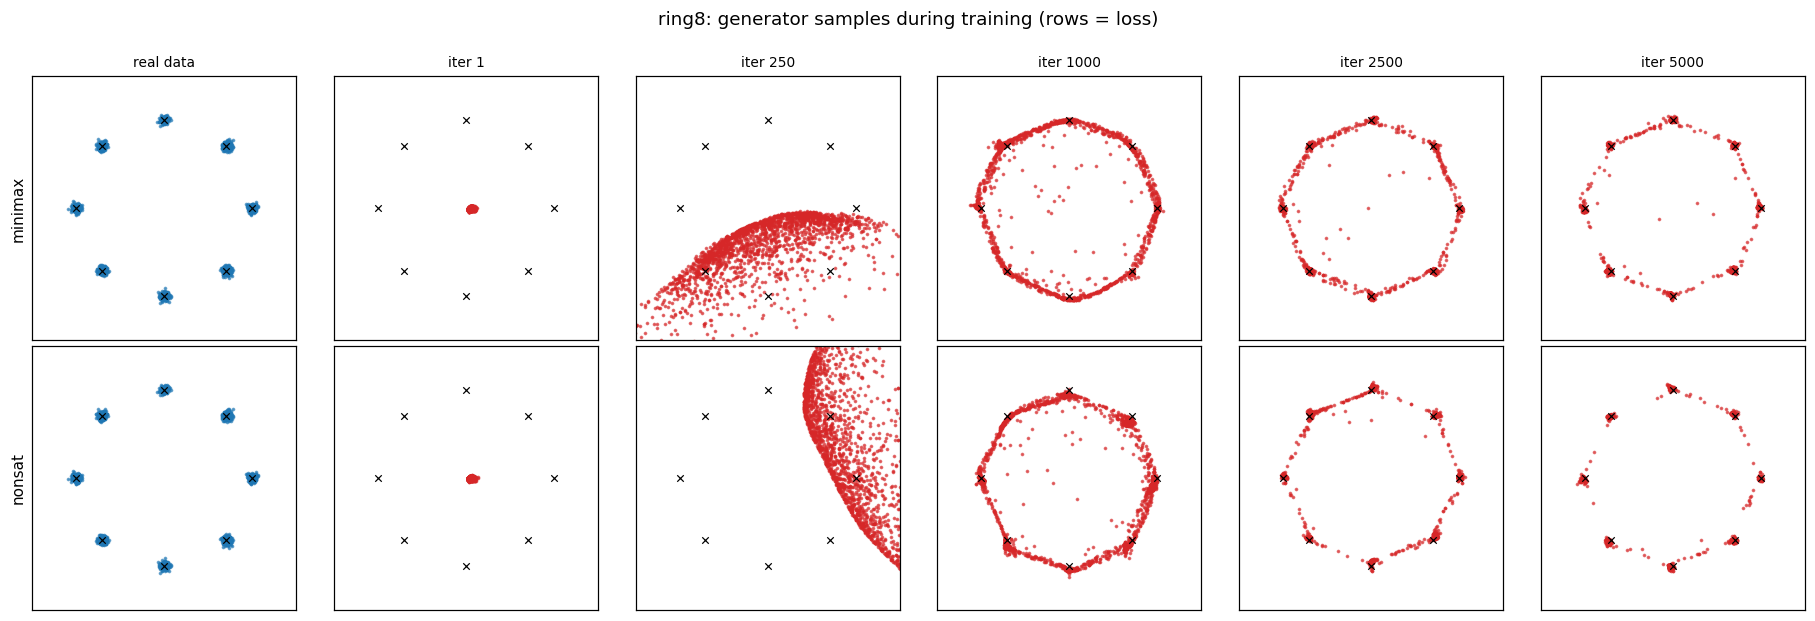

grid25  minimax  modes=19/25  hq=0.41  js=0.208   (26s)
grid25  nonsat   modes=20/25  hq=0.45  js=0.187   (26s)


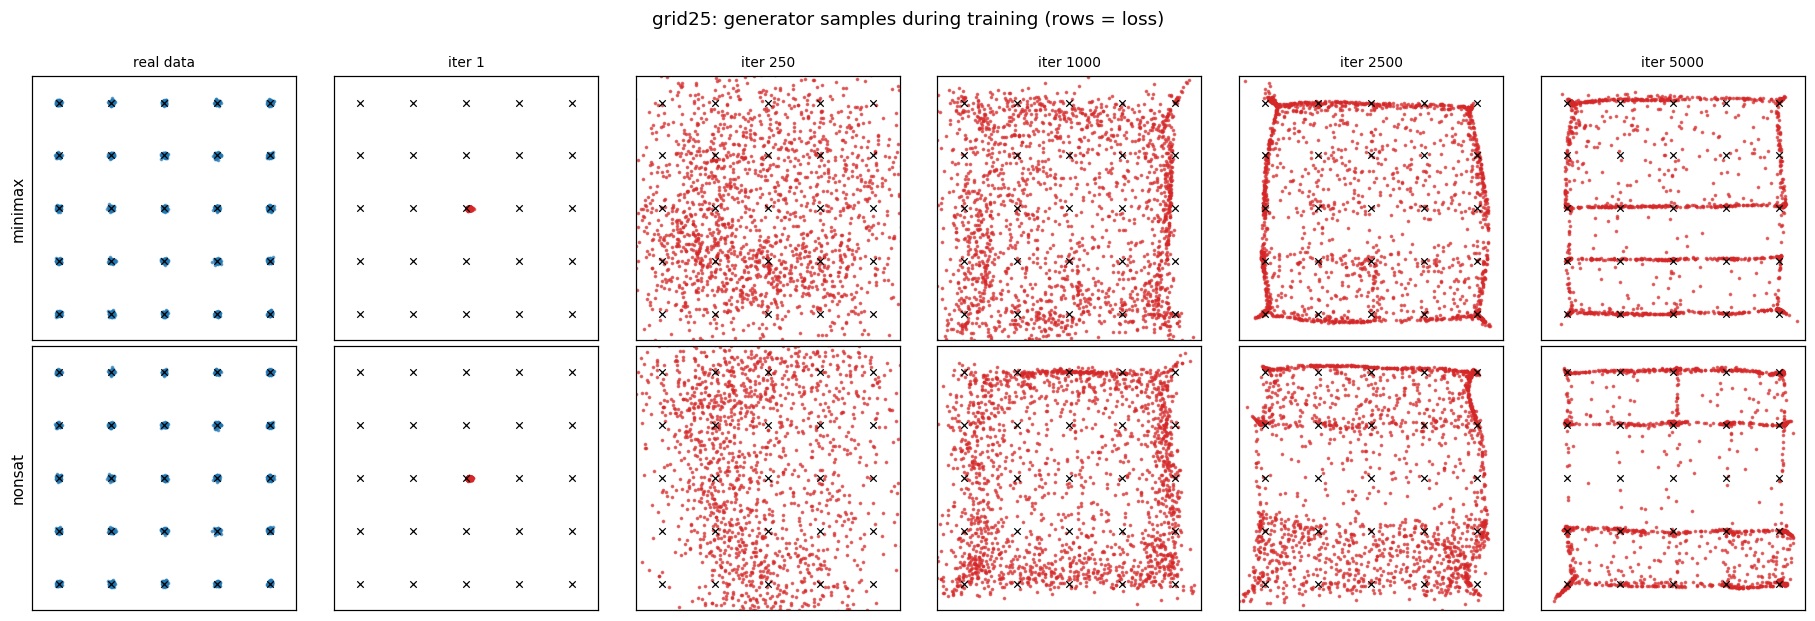

In [7]:
ring8, grid25 = ring(8), grid(5)
step = TOY_ITERS // 20
SNAPS_ALL = [1] + [step * i for i in range(1, 21)]
SNAP_SHOW = [1, step, 4 * step, 10 * step, 20 * step]

toy_runs = {}
for ds in (ring8, grid25):
    toy_runs[ds.name] = {}
    for loss in ("minimax", "nonsat"):
        t0 = time.time()
        r = run_toy(ds, Cfg(loss=loss, iters=TOY_ITERS, seed=0), SNAPS_ALL)
        toy_runs[ds.name][loss] = r
        print(f"{ds.name:7s} {loss:8s} modes={r['modes']}/{ds.K}  hq={r['hq']:.2f}  js={r['js']:.3f}   ({time.time()-t0:.0f}s)")
    plot_snapshots(toy_runs[ds.name], ds, SNAP_SHOW, title=f"{ds.name}: generator samples during training (rows = loss)")

### 3.2 Modes covered over training, and the gradient-saturation diagnostics

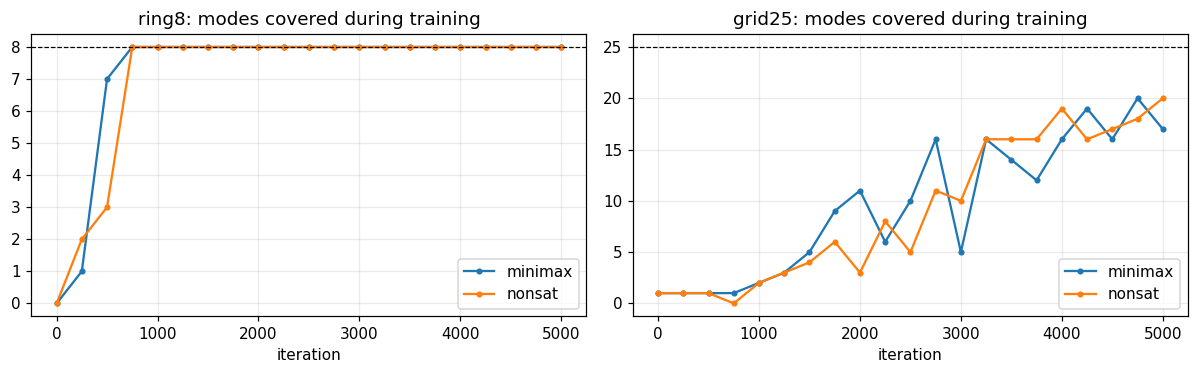

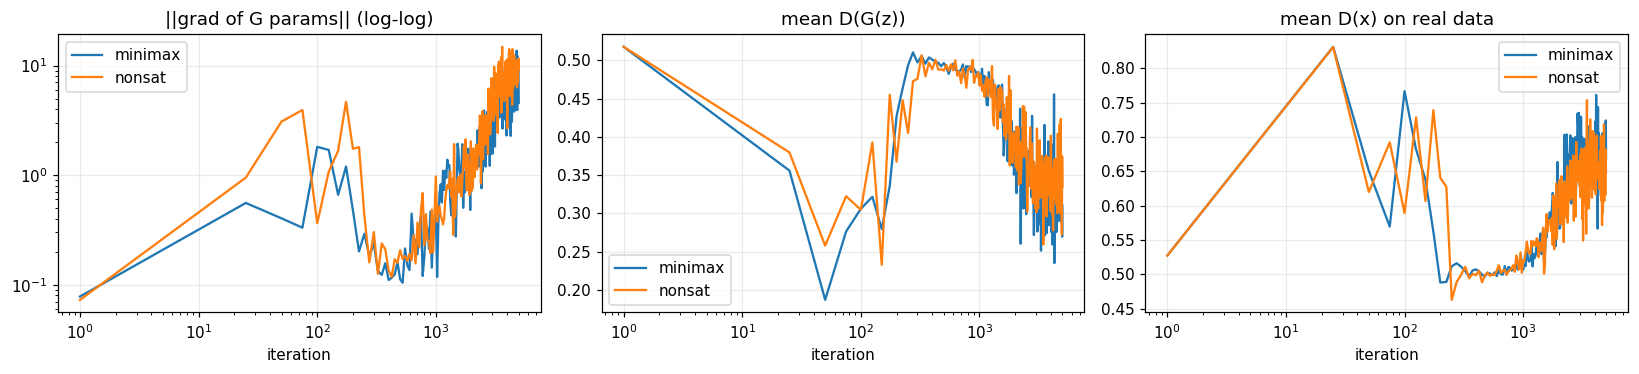

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, ds in zip(axes, (ring8, grid25)):
    for loss in ("minimax", "nonsat"):
        res = toy_runs[ds.name][loss]
        its = sorted(res["snaps"])
        ms = [mode_metrics(torch.tensor(res["snaps"][i], device=device), ds)["modes"] for i in its]
        ax.plot(its, ms, marker="o", ms=3, label=loss)
    ax.axhline(ds.K, color="k", ls="--", lw=0.8)
    ax.set_title(f"{ds.name}: modes covered during training"); ax.set_xlabel("iteration"); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for loss in ("minimax", "nonsat"):
    lg = toy_runs["grid25"][loss]["log"]
    axes[0].plot(lg["it"], lg["g_grad"], label=loss)
    axes[1].plot(lg["it"], lg["d_fake"], label=loss)
    axes[2].plot(lg["it"], lg["d_real"], label=loss)
axes[0].set_title("||grad of G params|| (log-log)"); axes[0].set_yscale("log")
axes[1].set_title("mean D(G(z))"); axes[2].set_title("mean D(x) on real data")
for a in axes: a.set_xscale("log"); a.set_xlabel("iteration"); a.legend()
plt.tight_layout(); plt.show()

### 3.3 Multi-seed comparison (don't trust a single seed!)

In [9]:
rows = []
for ds in (ring8, grid25):
    for loss in ("minimax", "nonsat"):
        for s in range(TOY_SEEDS):
            rows.append(dict(dataset=ds.name, loss=loss, seed=s,
                             **toy_metrics(ds, Cfg(loss=loss, iters=TOY_ITERS, seed=s))))
df_main = pd.DataFrame(rows)
display(df_main.groupby(["dataset", "loss"])[["modes", "hq", "js"]].agg(["mean", "std"]).round(3))

modes            hq            js       
                   mean    std   mean    std   mean    std
dataset loss                                              
grid25  minimax  20.333  3.215  0.453  0.102  0.150  0.074
        nonsat   17.667  2.517  0.551  0.132  0.203  0.051
ring8   minimax   8.000  0.000  0.949  0.006  0.001  0.000
        nonsat    7.667  0.577  0.960  0.005  0.032  0.049

### 3.4 Provoking mode collapse: the "Helvetica scenario"
The paper warns that G must not be trained too much without updating D, otherwise G collapses many $z$ to the same $x$. Here we change the D:G update ratio on `ring8` (non-saturating loss) and watch what happens.

D:G = 1:1 (base)       modes=8/8  hq=0.96  js=0.002
D:G = 1:5 (G-heavy)    modes=0/8  hq=0.00  js=1.000
D:G = 5:1 (D-heavy)    modes=2/8  hq=0.93  js=0.495


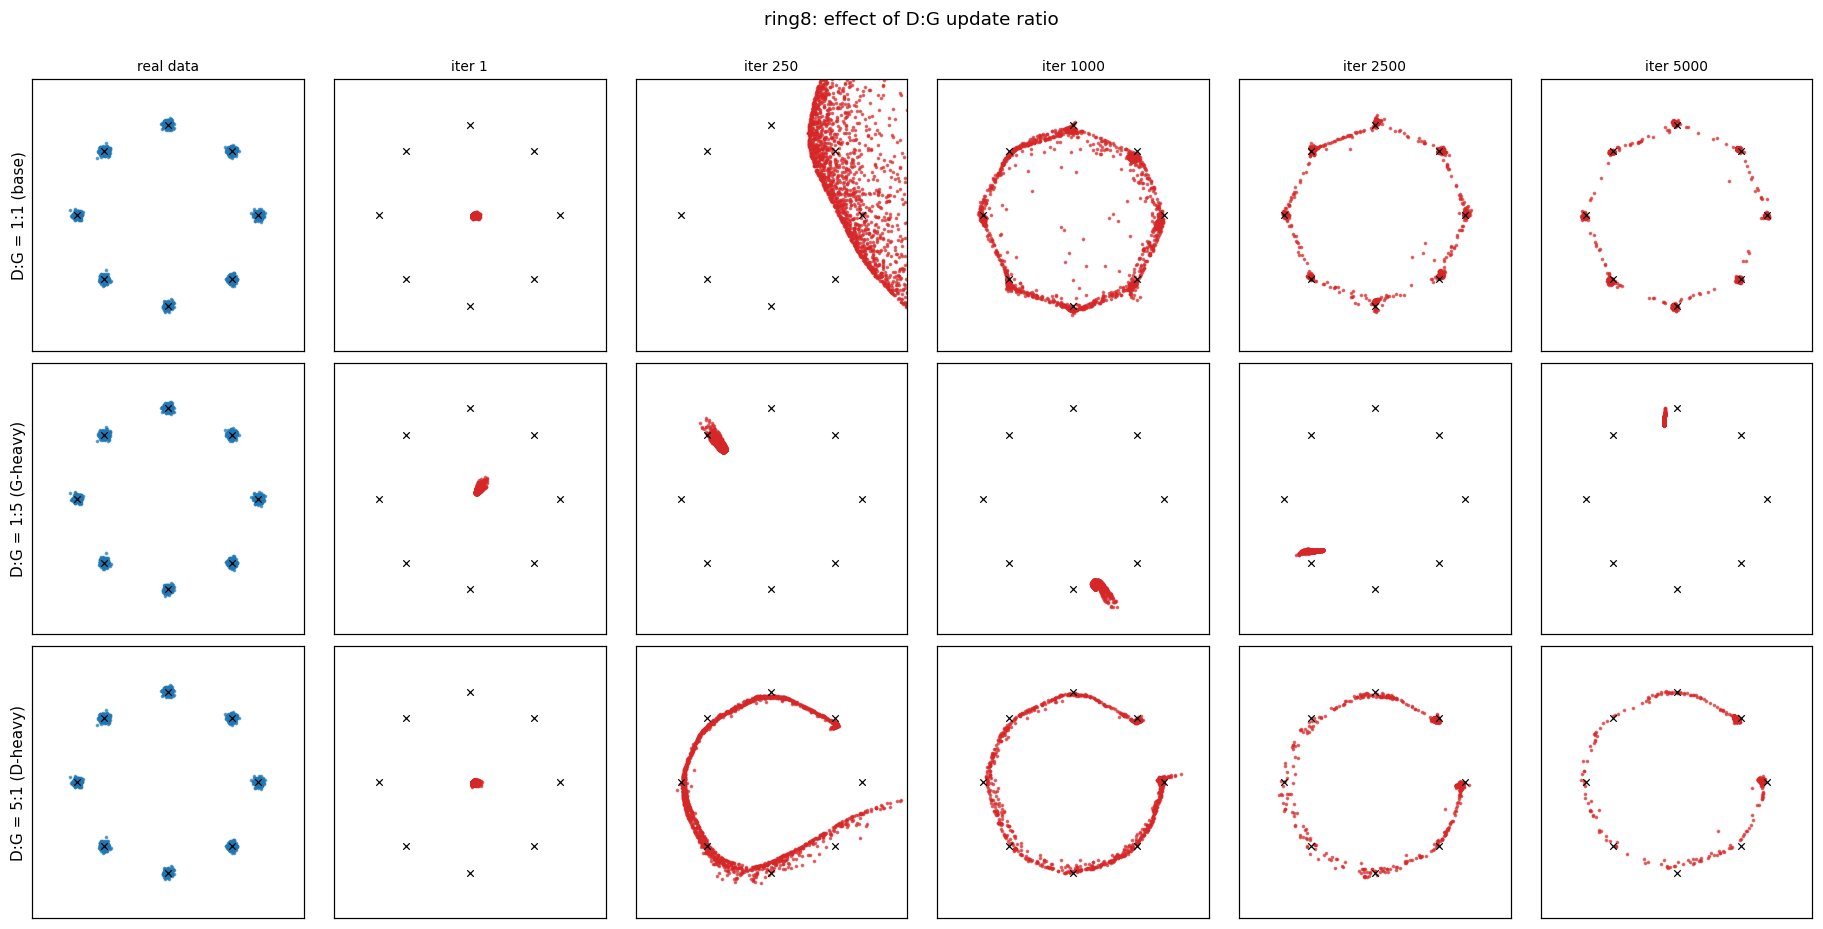

In [10]:
bal = {}
for name, ov in {"D:G = 1:1 (base)": {}, "D:G = 1:5 (G-heavy)": dict(g_steps=5), "D:G = 5:1 (D-heavy)": dict(d_steps=5)}.items():
    bal[name] = run_toy(ring8, Cfg(loss="nonsat", iters=TOY_ITERS, seed=0, **ov), SNAP_SHOW)
    print(f"{name:22s} modes={bal[name]['modes']}/8  hq={bal[name]['hq']:.2f}  js={bal[name]['js']:.3f}")
plot_snapshots(bal, ring8, SNAP_SHOW, title="ring8: effect of D:G update ratio")

## 4. Toy ablations — what actually matters?

We use the harder `grid25` dataset, **both losses**, and change **one factor at a time** relative to the base config (`Cfg` defaults). Results are averaged over `ABL_SEEDS` seeds; error bars are the seed-to-seed std.

> ⚠️ With only a couple of seeds, only treat a difference as real if it is clearly larger than the error bars. GANs are noisy.

In [11]:
TOY_ABL = {
    "D:G update ratio": {"1:1 (base)": {}, "5:1 (D-heavy)": dict(d_steps=5), "1:5 (G-heavy)": dict(g_steps=5)},
    "capacity (G/D width)": {"16/16": dict(g_hidden=16, d_hidden=16), "64/64": dict(g_hidden=64, d_hidden=64),
                             "128/128 (base)": {}, "256/256": dict(g_hidden=256, d_hidden=256),
                             "G256/D16": dict(g_hidden=256, d_hidden=16), "G16/D256": dict(g_hidden=16, d_hidden=256)},
    "noise dim z": {"1": dict(z_dim=1), "2 (base)": {}, "16": dict(z_dim=16)},
    "batch size": {"32": dict(batch_size=32), "256 (base)": {}},
    "Adam beta1": {"0.0": dict(beta1=0.0), "0.5 (base)": {}, "0.9": dict(beta1=0.9)},
    "learning rate": {"1e-4": dict(lr_g=1e-4, lr_d=1e-4), "5e-4 (base)": {}, "2e-3": dict(lr_g=2e-3, lr_d=2e-3),
                      "D 10x faster": dict(lr_d=5e-3), "G 10x faster": dict(lr_g=5e-3)},
    "depth (layers)": {"1": dict(g_layers=1, d_layers=1), "2": dict(g_layers=2, d_layers=2), "3 (base)": {}},
}

def run_toy_ablation(ds, base, factors, losses=("minimax", "nonsat"), seeds=range(2)):
    rows = []
    for fac, opts in factors.items():
        t0 = time.time()
        for opt_name, ov in opts.items():
            for loss in losses:
                for s in seeds:
                    cfg = replace(base, loss=loss, seed=s, **ov)
                    rows.append(dict(factor=fac, option=opt_name, loss=loss, seed=s, **toy_metrics(ds, cfg)))
        print(f"finished factor '{fac}'  ({time.time()-t0:.0f}s)")
    return pd.DataFrame(rows)

# To save time you can run a subset, e.g. {k: TOY_ABL[k] for k in ["D:G update ratio", "capacity (G/D width)"]}
df_abl = run_toy_ablation(grid25, Cfg(iters=TOY_ITERS), TOY_ABL, seeds=range(ABL_SEEDS))

finished factor 'D:G update ratio'  (607s)
finished factor 'capacity (G/D width)'  (508s)
finished factor 'noise dim z'  (203s)
finished factor 'batch size'  (102s)
finished factor 'Adam beta1'  (206s)
finished factor 'learning rate'  (417s)
finished factor 'depth (layers)'  (157s)


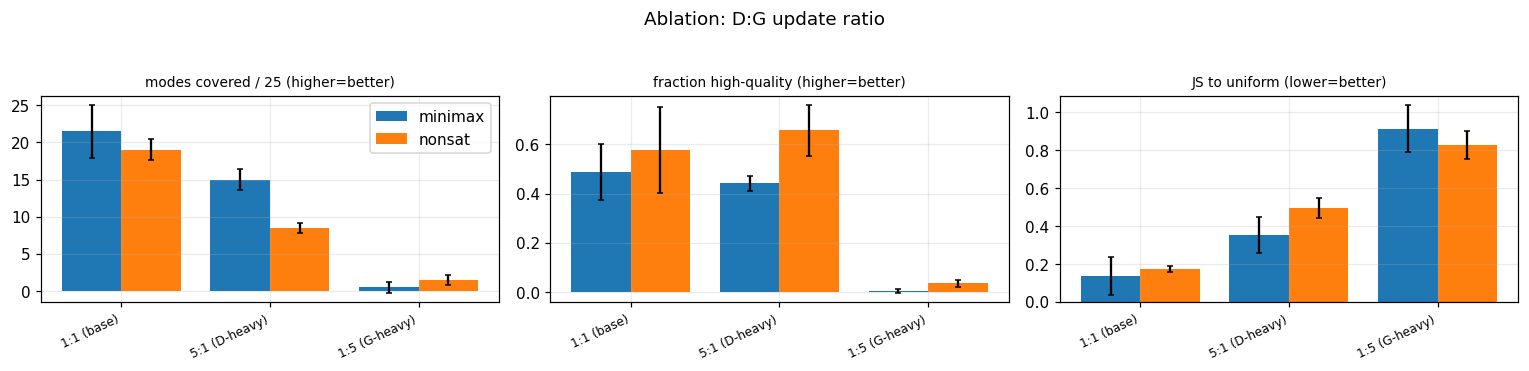

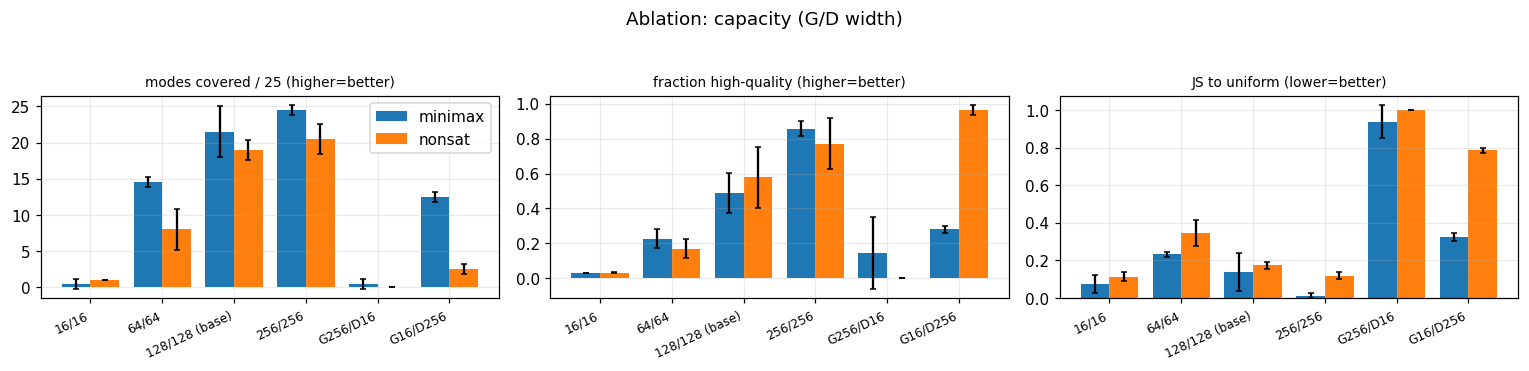

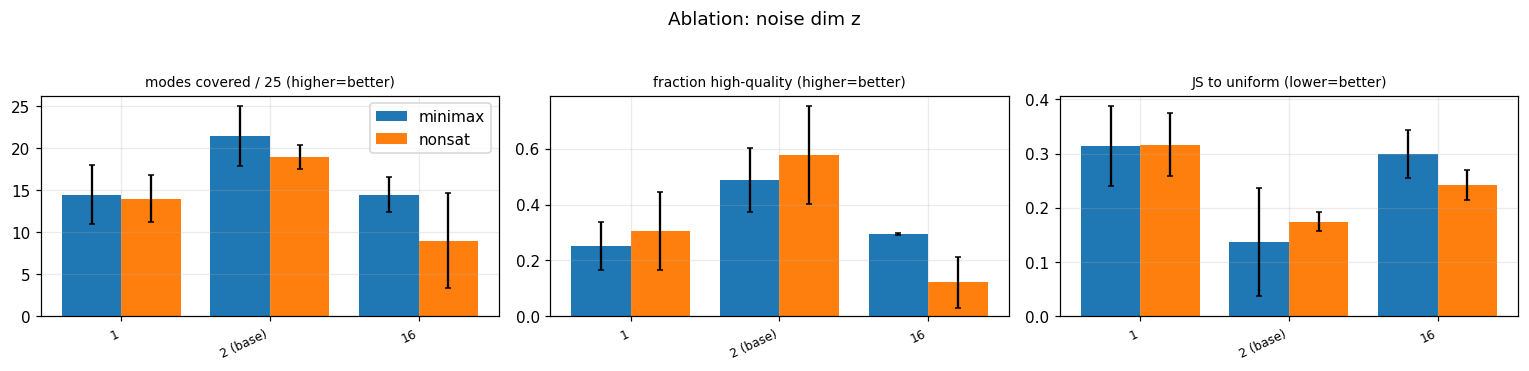

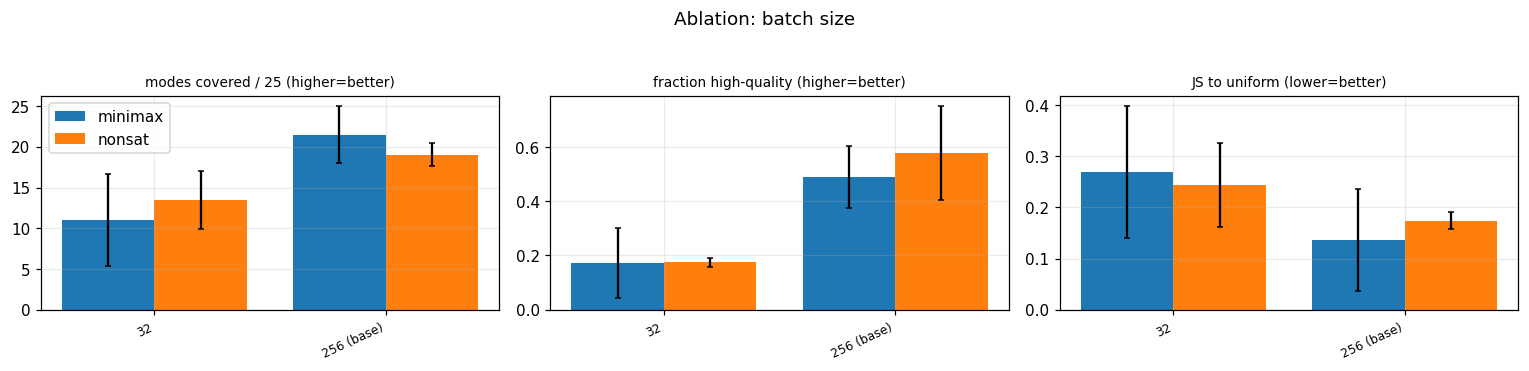

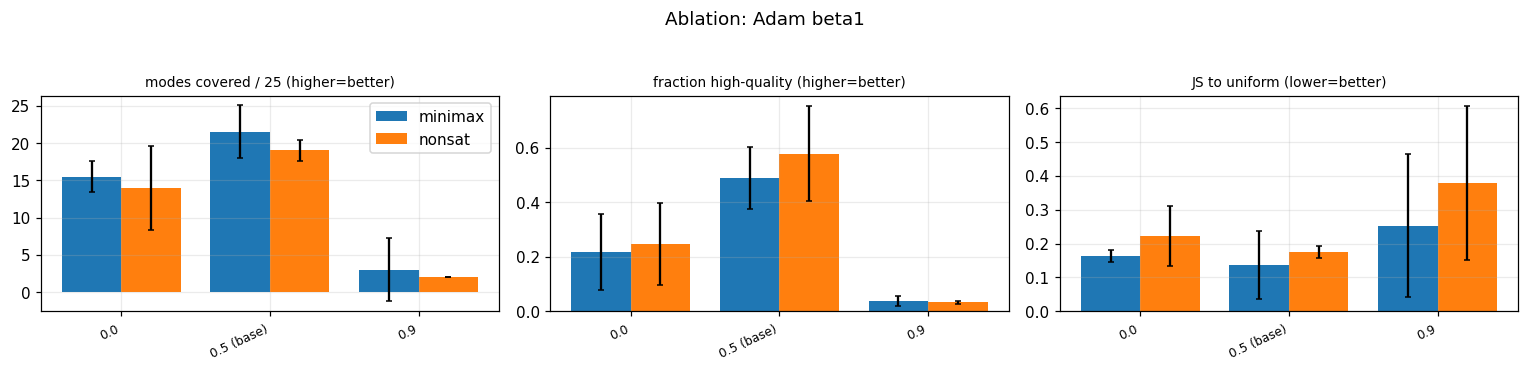

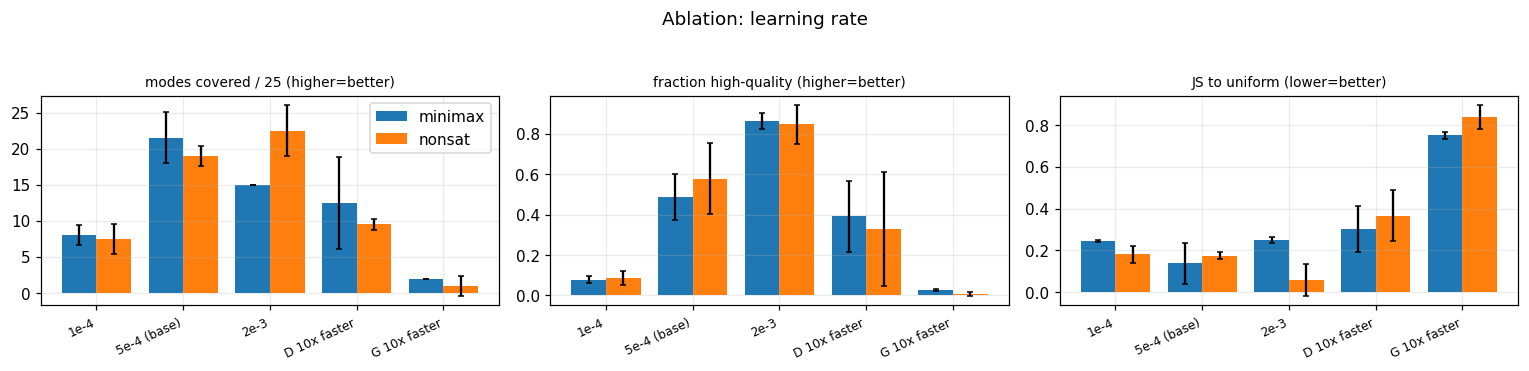

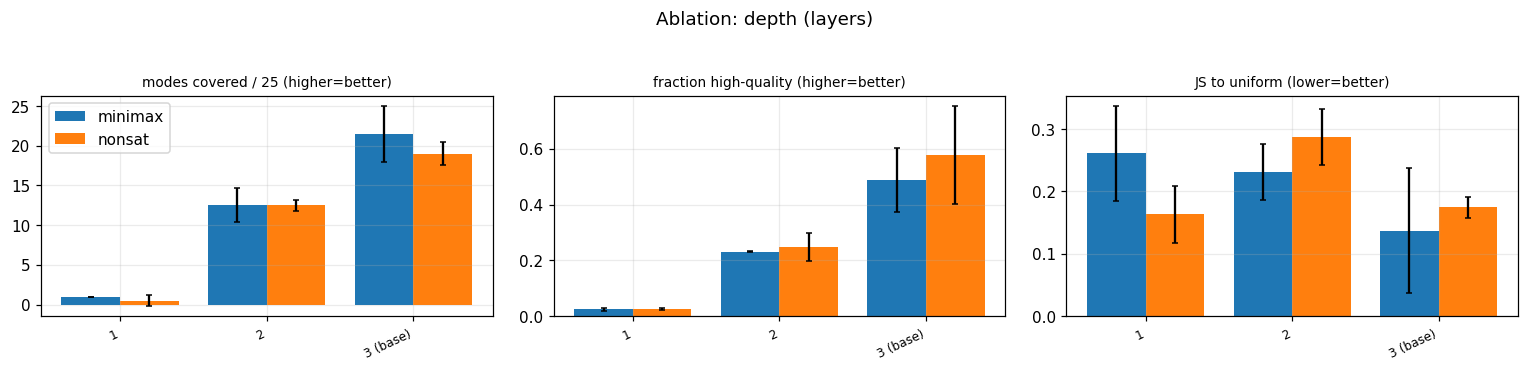

modes             hq             js  \
loss                                minimax nonsat minimax nonsat minimax   
factor               option                                                 
Adam beta1           0.0               15.5   14.0   0.217  0.246   0.164   
                     0.5 (base)        21.5   19.0   0.489  0.578   0.137   
                     0.9                3.0    2.0   0.038  0.032   0.253   
D:G update ratio     1:1 (base)        21.5   19.0   0.489  0.578   0.137   
                     1:5 (G-heavy)      0.5    1.5   0.005  0.035   0.913   
                     5:1 (D-heavy)     15.0    8.5   0.442  0.657   0.353   
batch size           256 (base)        21.5   19.0   0.489  0.578   0.137   
                     32                11.0   13.5   0.171  0.174   0.269   
capacity (G/D width) 128/128 (base)    21.5   19.0   0.489  0.578   0.137   
                     16/16              0.5    1.0   0.029  0.032   0.074   
                     256/256           24.5   20.5   0.857  0.771   0.013   
                     64/64             14.5    8.0   0.227  0.169   0.233   
                     G16/D256          12.5    2.5   0.281  0.965   0.326   
                     G256/D16           0.5    0.0   0.145  0.000   0.939   
depth (layers)       1                  1.0    0.5   0.025  0.025   0.261   
                     2                 12.5   12.5   0.232  0.247   0.231   
                     3 (base)          21.5   19.0   0.489  0.578   0.137   
learning rate        1e-4               8.0    7.5   0.078  0.088   0.247   
                     2e-3              15.0   22.5   0.863  0.846   0.250   
                     5e-4 (base)       21.5   19.0   0.489  0.578   0.137   
                     D 10x faster      12.5    9.5   0.392  0.330   0.302   
                     G 10x faster       2.0    1.0   0.027  0.008   0.751   
noise dim z          1                 14.5   14.0   0.252  0.304   0.314   
                     16                14.5    9.0   0.294  0.121   0.300   
                     2 (base)          21.5   19.0   0.489  0.578   0.137   

                                            
loss                                nonsat  
factor               option                 
Adam beta1           0.0             0.222  
                     0.5 (base)      0.174  
                     0.9             0.379  
D:G update ratio     1:1 (base)      0.174  
                     1:5 (G-heavy)   0.826  
                     5:1 (D-heavy)   0.495  
batch size           256 (base)      0.174  
                     32              0.244  
capacity (G/D width) 128/128 (base)  0.174  
                     16/16           0.114  
                     256/256         0.118  
                     64/64           0.347  
                     G16/D256        0.785  
                     G256/D16        1.000  
depth (layers)       1               0.163  
                     2               0.287  
                     3 (base)        0.174  
learning rate        1e-4            0.180  
                     2e-3            0.058  
                     5e-4 (base)     0.174  
                     D 10x faster    0.366  
                     G 10x faster    0.837  
noise dim z          1               0.317  
                     16              0.242  
                     2 (base)        0.174

In [13]:
def plot_ablation(df, factor):
    d = df[df.factor == factor]
    options = list(dict.fromkeys(d.option))
    losses = sorted(d.loss.unique())
    w = 0.8 / len(losses)
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
    for ax, (m, lab) in zip(axes, [("modes", "modes covered / 25 (higher=better)"),
                                   ("hq", "fraction high-quality (higher=better)"),
                                   ("js", "JS to uniform (lower=better)")]):
        for i, loss in enumerate(losses):
            g = d[d.loss == loss].groupby("option")[m].agg(["mean", "std"]).reindex(options)
            ax.bar(np.arange(len(options)) + i * w, g["mean"], w, yerr=g["std"].fillna(0), capsize=2, label=loss)
        ax.set_xticks(np.arange(len(options)) + w * (len(losses) - 1) / 2)
        ax.set_xticklabels(options, rotation=25, ha="right", fontsize=8); ax.set_title(lab, fontsize=9)
    axes[0].legend(); fig.suptitle(f"Ablation: {factor}", y=1.04); plt.tight_layout(); plt.show()

for fac in df_abl.factor.unique():
    plot_ablation(df_abl, fac)

summary = (df_abl.groupby(["factor", "option", "loss"])[["modes", "hq", "js"]].mean().round(3)
           .unstack("loss"))
display(summary)

## 5. MNIST

Faithful-ish to the paper: **MLP generator** (ReLU hidden units, sigmoid output) and **maxout discriminator with dropout**. Data are real-valued pixels in [0,1], flattened to 784-d. We use the standard 50k/10k/10k train/val/test split (validation set is used only to choose the Parzen σ).

Deviation: we use **Adam (β₁=0.5)** instead of the paper's SGD+momentum because it is far less fiddly; `opt="sgd"` is available in `Cfg` if you want to try the original.

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 489kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.62MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.4MB/s]


train (50000, 784) | val (10000, 784) | test (10000, 784) | range 0.0 1.0


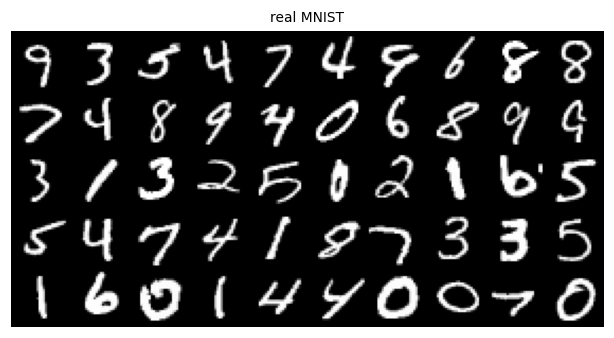

In [14]:
from torchvision import datasets
_tr = datasets.MNIST("./data", train=True, download=True)
_te = datasets.MNIST("./data", train=False, download=True)
X_all = (_tr.data.float() / 255.).view(-1, 784).to(device)
y_all = _tr.targets.to(device)
Xte = (_te.data.float() / 255.).view(-1, 784).to(device)
yte = _te.targets.to(device)

perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0)).to(device)
Xtr, ytr = X_all[perm[:50000]], y_all[perm[:50000]]
Xva = X_all[perm[50000:]]
print("train", tuple(Xtr.shape), "| val", tuple(Xva.shape), "| test", tuple(Xte.shape), "| range", Xtr.min().item(), Xtr.max().item())

def sample_real_mnist(n):
    return Xtr[torch.randint(0, Xtr.shape[0], (n,), device=device)]

def to_grid(x, nrow=10):
    x = x.detach().cpu().view(-1, 28, 28).numpy()
    rows = int(np.ceil(len(x) / nrow))
    canvas = np.zeros((rows * 28, nrow * 28))
    for i in range(len(x)):
        r, c = divmod(i, nrow)
        canvas[r * 28:(r + 1) * 28, c * 28:(c + 1) * 28] = x[i]
    return canvas

def show(x, nrow=10, title="", ax=None):
    if ax is None:
        plt.figure(figsize=(nrow * 0.7, max(1.0, np.ceil(len(x) / nrow) * 0.7)))
        ax = plt.gca()
    ax.imshow(to_grid(x, nrow), cmap="gray", vmin=0, vmax=1); ax.axis("off"); ax.set_title(title, fontsize=9)

show(Xtr[:50], nrow=10, title="real MNIST")
plt.show()

def mnist_cfg(**kw):
    base = dict(loss="nonsat", z_dim=100, g_hidden=1200, g_layers=2, d_hidden=240, d_layers=2,
                d_act="maxout", maxout_k=5, d_dropout=0.5, opt="adam", lr_g=2e-4, lr_d=2e-4,
                beta1=0.5, batch_size=100, iters=MNIST_ITERS)
    base.update(kw)
    return Cfg(**base)

### 5.1 Evaluation tools (needed during training for learning curves)

1. **Parzen-window log-likelihood** (paper's metric): fit a Gaussian KDE on 10 000 generated samples, choose σ by cross-validation on the *validation* set (grid `logspace(-1, 0, 10)`, as in Breuleux et al. / the paper), report the mean log-likelihood on the *test* set. The paper itself says this estimator has "somewhat high variance and does not perform well in high dimensional spaces" — treat it as a coarse signal.
2. **Classifier-based coverage** (extra, to study mode collapse on MNIST): train a small CNN on real MNIST, then look at the class histogram of generated digits, a normalised class entropy (1.0 = all 10 classes equally represented) and an Inception-style score $\exp(\mathbb{E}_x \mathrm{KL}(p(y|x)\,\|\,p(y)))$ (max 10).

In [15]:
# ---------------- Parzen window ----------------
SIGMAS = np.logspace(-1, 0, 10)

@torch.no_grad()
def parzen_ll(samples, x, sigma, bs=1000):
    # per-example log p(x) under an isotropic-Gaussian KDE centred on `samples`
    N, D = samples.shape
    g2 = (samples ** 2).sum(1)
    out = []
    for i in range(0, len(x), bs):
        xb = x[i:i + bs]
        d2 = (xb ** 2).sum(1, keepdim=True) - 2 * xb @ samples.T + g2[None]
        a = -d2.clamp_min(0) / (2 * sigma ** 2)
        out.append(torch.logsumexp(a, 1) - math.log(N) - D * (math.log(sigma) + 0.5 * math.log(2 * math.pi)))
    return torch.cat(out)

@torch.no_grad()
def parzen_eval(samples, sigmas=SIGMAS):
    val = [parzen_ll(samples, Xva, float(s)).mean().item() for s in sigmas]
    best = float(sigmas[int(np.argmax(val))])
    ll = parzen_ll(samples, Xte, best)
    return dict(sigma=best, ll_mean=ll.mean().item(), ll_se=(ll.std() / math.sqrt(len(ll))).item())

# ---------------- classifier for coverage metrics ----------------
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 32, 3); self.c2 = nn.Conv2d(32, 64, 3)
        self.fc1 = nn.Linear(64 * 12 * 12, 128); self.fc2 = nn.Linear(128, 10)
    def forward(self, x):
        x = x.view(-1, 1, 28, 28)
        x = F.relu(self.c1(x)); x = F.max_pool2d(F.relu(self.c2(x)), 2)
        return self.fc2(F.relu(self.fc1(x.flatten(1))))

def train_classifier(epochs=2):
    set_seed(0)
    clf = SmallCNN().to(device); opt = torch.optim.Adam(clf.parameters(), 1e-3)
    for _ in range(epochs):
        p = torch.randperm(Xtr.shape[0], device=device)
        for i in range(0, len(p), 128):
            idx = p[i:i + 128]
            loss = F.cross_entropy(clf(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    return clf.eval()

clf = train_classifier()

@torch.no_grad()
def class_probs(x, bs=1000):
    return torch.cat([F.softmax(clf(x[i:i + bs]), 1) for i in range(0, len(x), bs)])

print("classifier test accuracy:", (class_probs(Xte).argmax(1) == yte).float().mean().item())

@torch.no_grad()
def classifier_metrics(x):
    p = class_probs(x)
    py = p.mean(0)
    kl = (p * (p.clamp_min(1e-12).log() - py.clamp_min(1e-12).log())).sum(1).mean()
    ent = -(py * py.clamp_min(1e-12).log()).sum() / math.log(10)
    hist = torch.bincount(p.argmax(1), minlength=10).float() / len(p)
    return dict(IS=kl.exp().item(), class_entropy=ent.item(), conf=p.max(1)[0].mean().item(), hist=hist.cpu().numpy())

# eval noise comes from its own generator so evaluation never perturbs training randomness
def eval_noise(n, z_dim, seed=1234):
    g = torch.Generator(device=device); g.manual_seed(seed)
    return torch.randn(n, z_dim, device=device, generator=g)

@torch.no_grad()
def generate(G, cfg, n=10000, bs=5000):
    z = eval_noise(n, cfg.z_dim)
    return torch.cat([G(z[i:i + bs]) for i in range(0, n, bs)])

@torch.no_grad()
def mnist_eval(G, cfg, n=10000):
    s = generate(G, cfg, n)
    p = parzen_eval(s)
    return dict(parzen_ll=p["ll_mean"], parzen_se=p["ll_se"], sigma=p["sigma"], **classifier_metrics(s))

print("classifier metrics on REAL test data (reference):",
      {k: (round(v, 3) if not isinstance(v, np.ndarray) else None) for k, v in classifier_metrics(Xte).items()})

classifier test accuracy: 0.9863999485969543
classifier metrics on REAL test data (reference): {'IS': 9.489, 'class_entropy': 0.999, 'conf': 0.984, 'hist': None}


### 5.2 Train: non-saturating vs minimax (same seed, same architecture)

In [16]:
def run_mnist(cfg, eval_points=8):
    curve, snaps = [], {}
    fz = eval_noise(100, cfg.z_dim, seed=0)
    its = sorted({int(cfg.iters * (i + 1) / eval_points) for i in range(eval_points)})
    def cb(it, G, D):
        with torch.no_grad():
            snaps[it] = G(fz).cpu()
        m = mnist_eval(G, cfg)
        curve.append(dict(it=it, **{k: v for k, v in m.items() if k != "hist"}))
        print(f"  it {it:6d}  parzen_ll={m['parzen_ll']:8.1f}  IS={m['IS']:.2f}  class_ent={m['class_entropy']:.3f}")
    G, D, log = train_gan(cfg, sample_real_mnist, 784, "sigmoid", cb_iters=its, callback=cb, log_every=50)
    return dict(G=G, D=D, log=log, curve=pd.DataFrame(curve), snaps=snaps, final=mnist_eval(G, cfg), cfg=cfg)

mnist_runs = {}
for loss in ("nonsat", "minimax"):
    print(f"=== MNIST | loss = {loss} ===")
    t0 = time.time()
    mnist_runs[loss] = run_mnist(mnist_cfg(loss=loss))
    print(f"  done in {time.time()-t0:.0f}s")

=== MNIST | loss = nonsat ===
  it   2500  parzen_ll=  -272.6  IS=1.05  class_ent=0.064
  it   5000  parzen_ll=  -285.1  IS=1.00  class_ent=0.517
  it   7500  parzen_ll=  -301.0  IS=1.01  class_ent=0.286
  it  10000  parzen_ll=  -339.4  IS=1.00  class_ent=0.435
  it  12500  parzen_ll=  -293.5  IS=1.00  class_ent=0.003
  it  15000  parzen_ll=  -309.8  IS=1.00  class_ent=0.002
  it  17500  parzen_ll=  -306.7  IS=1.00  class_ent=0.004
  it  20000  parzen_ll=  -321.4  IS=1.00  class_ent=0.018
  done in 115s
=== MNIST | loss = minimax ===
  it   2500  parzen_ll=  -215.1  IS=2.09  class_ent=0.553
  it   5000  parzen_ll=  -233.4  IS=1.91  class_ent=0.667
  it   7500  parzen_ll=  -275.8  IS=1.70  class_ent=0.386
  it  10000  parzen_ll=  -400.5  IS=1.58  class_ent=0.259
  it  12500  parzen_ll=  -396.2  IS=1.44  class_ent=0.205
  it  15000  parzen_ll=  -403.1  IS=1.48  class_ent=0.349
  it  17500  parzen_ll=  -429.7  IS=1.04  class_ent=0.103
  it  20000  parzen_ll=  -435.4  IS=1.03  class_ent=0.

### 5.3 Samples, learning curves, training diagnostics

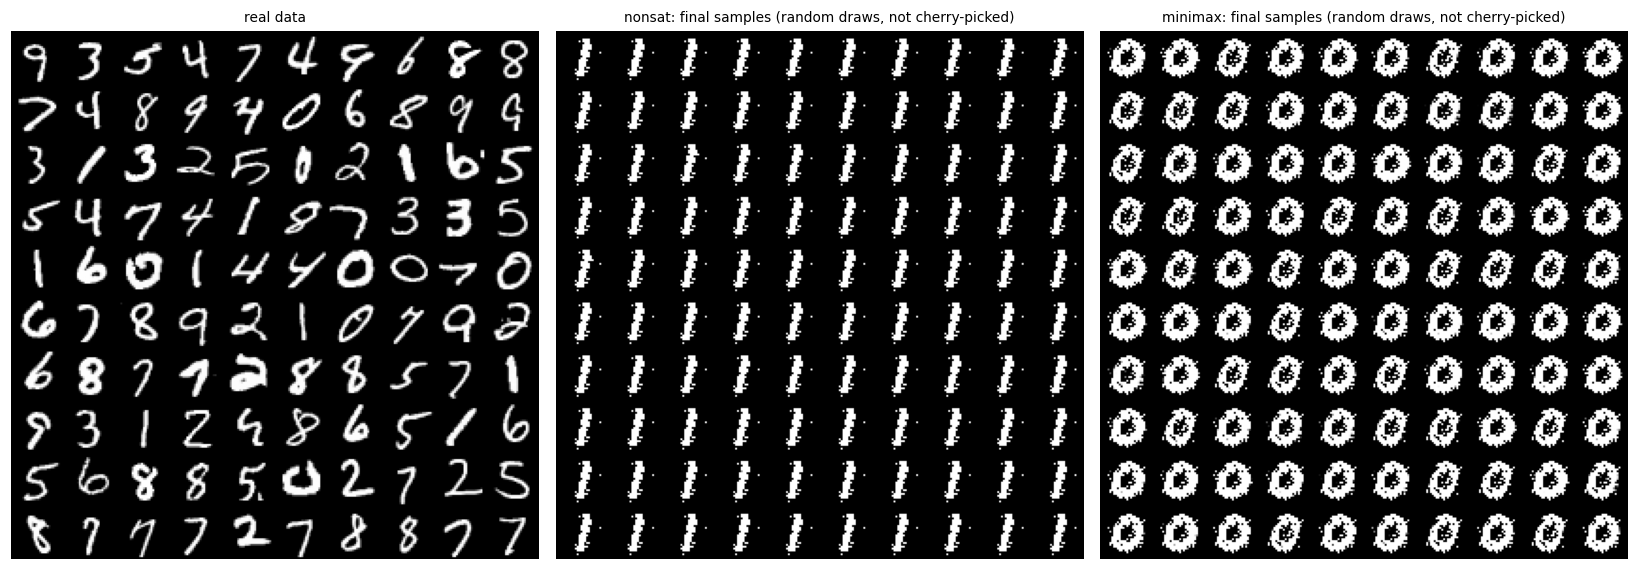

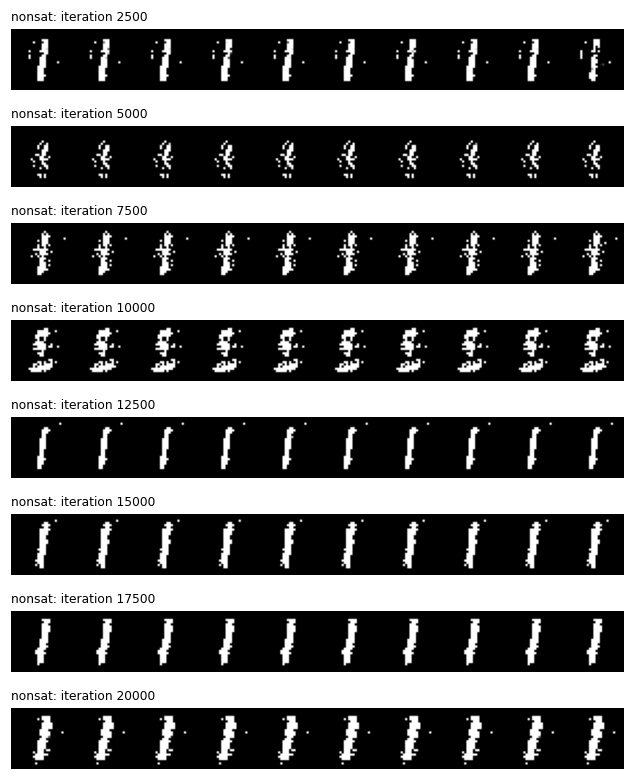

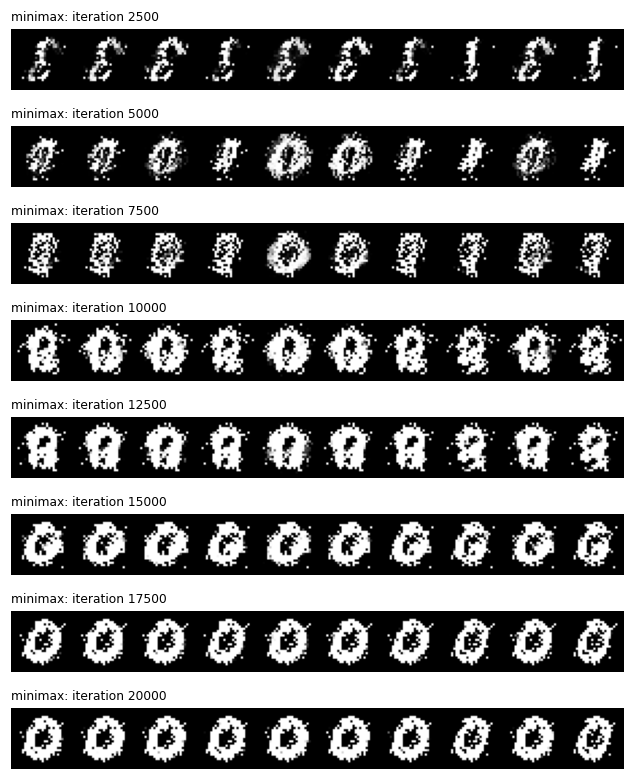

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2))
show(Xtr[:100], 10, "real data", ax=axes[0])
for ax, loss in zip(axes[1:], ("nonsat", "minimax")):
    show(generate(mnist_runs[loss]["G"], mnist_runs[loss]["cfg"], 100), 10, f"{loss}: final samples (random draws, not cherry-picked)", ax=ax)
plt.tight_layout(); plt.show()

for loss in ("nonsat", "minimax"):
    r = mnist_runs[loss]
    its = sorted(r["snaps"])
    fig, axes = plt.subplots(len(its), 1, figsize=(8, 0.9 * len(its)))
    for ax, it in zip(np.atleast_1d(axes), its):
        show(r["snaps"][it][:10], 10, "", ax=ax); ax.set_title(f"{loss}: iteration {it}", fontsize=8, loc="left")
    plt.tight_layout(); plt.show()

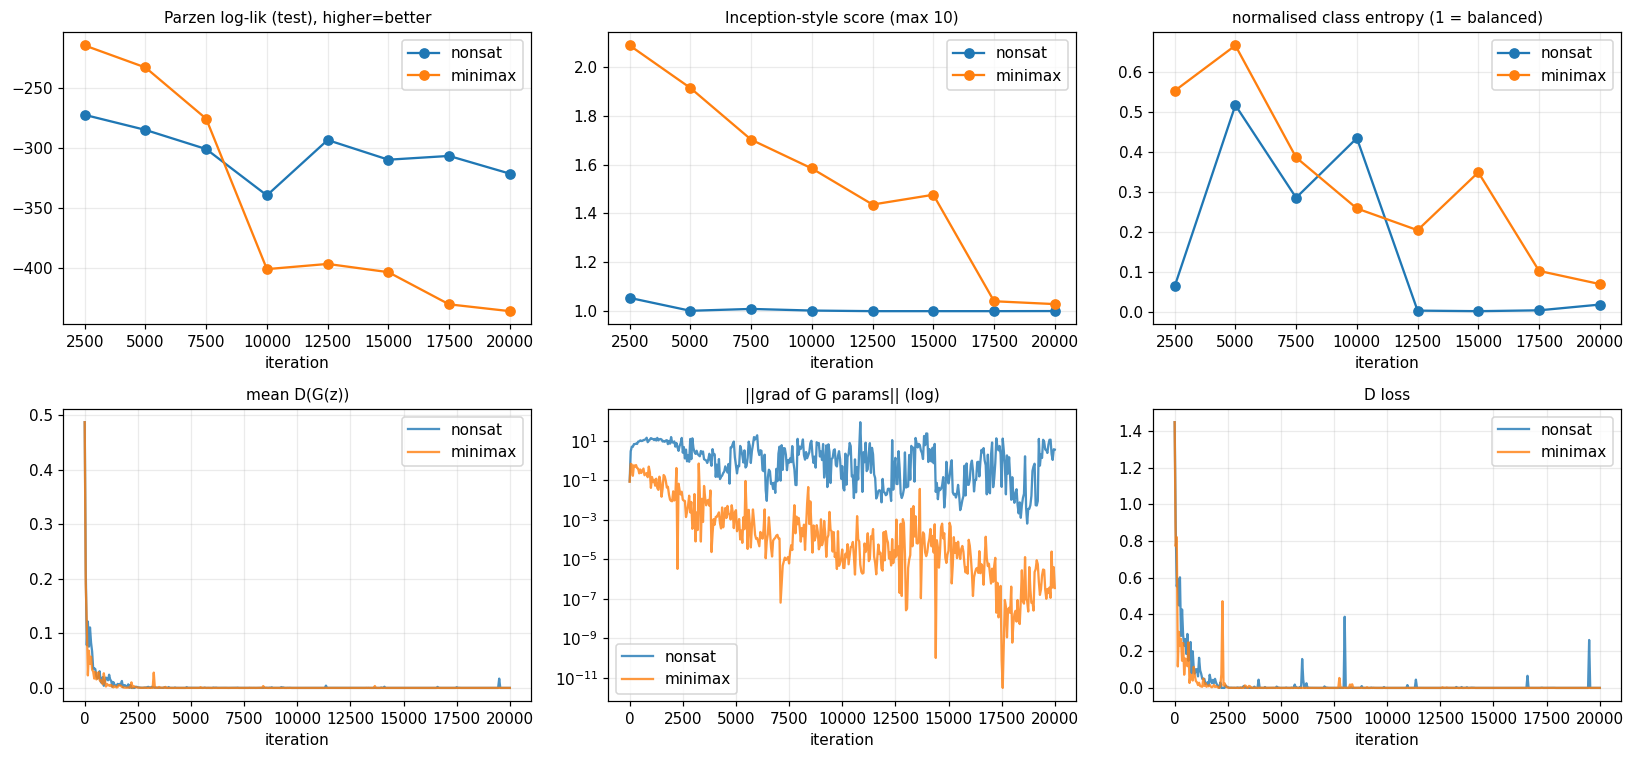

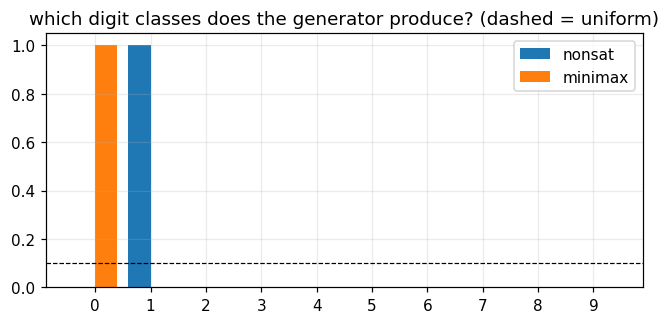

In [18]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for loss in ("nonsat", "minimax"):
    c, lg = mnist_runs[loss]["curve"], mnist_runs[loss]["log"]
    axes[0, 0].plot(c.it, c.parzen_ll, marker="o", label=loss)
    axes[0, 1].plot(c.it, c.IS, marker="o", label=loss)
    axes[0, 2].plot(c.it, c.class_entropy, marker="o", label=loss)
    axes[1, 0].plot(lg["it"], lg["d_fake"], label=loss, alpha=0.8)
    axes[1, 1].plot(lg["it"], lg["g_grad"], label=loss, alpha=0.8)
    axes[1, 2].plot(lg["it"], lg["d_loss"], label=loss, alpha=0.8)
for ax, t in zip(axes.ravel(), ["Parzen log-lik (test), higher=better", "Inception-style score (max 10)", "normalised class entropy (1 = balanced)",
                                "mean D(G(z))", "||grad of G params|| (log)", "D loss"]):
    ax.set_title(t, fontsize=10); ax.legend(); ax.set_xlabel("iteration")
axes[1, 1].set_yscale("log")
plt.tight_layout(); plt.show()

# class histogram of generated digits
fig, ax = plt.subplots(figsize=(7, 3))
for i, loss in enumerate(("nonsat", "minimax")):
    ax.bar(np.arange(10) + i * 0.4, mnist_runs[loss]["final"]["hist"], 0.4, label=loss)
ax.axhline(0.1, color="k", ls="--", lw=0.8); ax.set_xticks(np.arange(10) + 0.2); ax.set_xticklabels(range(10))
ax.set_title("which digit classes does the generator produce? (dashed = uniform)"); ax.legend(); plt.show()

median NN distance to train set | generated: 4.59 | real held-out test: 4.43
(generated << test would indicate memorisation)


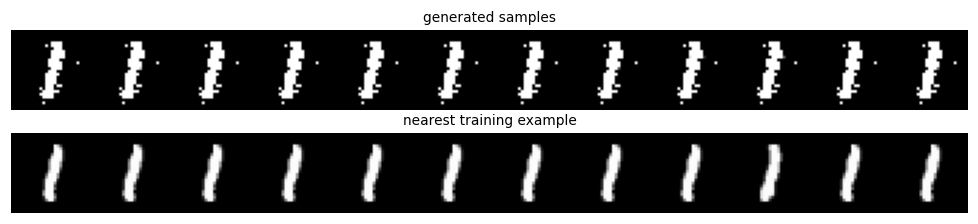

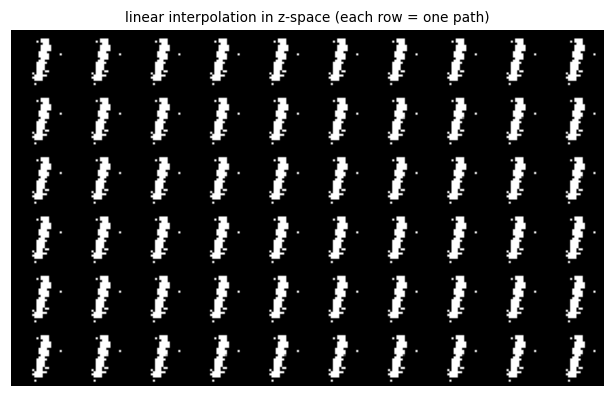

In [19]:
@torch.no_grad()
def nearest_train(x, bank=None, bs=500):
    bank = Xtr if bank is None else bank
    b2 = (bank ** 2).sum(1)
    idx, dist = [], []
    for i in range(0, len(x), bs):
        xb = x[i:i + bs]
        d2 = (xb ** 2).sum(1, keepdim=True) - 2 * xb @ bank.T + b2[None]
        m, j = d2.min(1)
        idx.append(j); dist.append(m.clamp_min(0).sqrt())
    return torch.cat(idx), torch.cat(dist)

best_loss = "nonsat"
G, cfg = mnist_runs[best_loss]["G"], mnist_runs[best_loss]["cfg"]
with torch.no_grad():
    s = generate(G, cfg, 1000)
idx, dist_gen = nearest_train(s)
_, dist_test = nearest_train(Xte[:1000])
print(f"median NN distance to train set | generated: {dist_gen.median().item():.2f} | real held-out test: {dist_test.median().item():.2f}")
print("(generated << test would indicate memorisation)")

fig, axes = plt.subplots(2, 1, figsize=(9, 2.1))
show(s[:12], 12, "generated samples", ax=axes[0]); show(Xtr[idx[:12]], 12, "nearest training example", ax=axes[1])
plt.tight_layout(); plt.show()

@torch.no_grad()
def interpolate(G, cfg, rows=6, steps=10):
    z0, z1 = torch.randn(rows, cfg.z_dim, device=device), torch.randn(rows, cfg.z_dim, device=device)
    t = torch.linspace(0, 1, steps, device=device).view(1, -1, 1)
    z = (1 - t) * z0[:, None] + t * z1[:, None]
    return G(z.view(-1, cfg.z_dim))

set_seed(1)
show(interpolate(G, cfg), 10, "linear interpolation in z-space (each row = one path)")
plt.show()

## 6. Reproducing the key result (paper Table 1, MNIST column)

Paper (quoted from Table 1, mean log-likelihood on MNIST test set, Parzen window): DBN 138 ± 2, Stacked CAE 121 ± 1.6, Deep GSN 214 ± 1.1, **Adversarial nets 225 ± 2**.

We cannot re-train DBN / CAE / GSN here, so we compare our GAN against the quoted numbers and against *sanity baselines* computed with the **same Parzen code**: a KDE built from 10 000 real training images (a rough "ceiling" for this estimator), and an untrained generator (a floor). **Exact agreement with 225 is not expected** (different architecture details, optimiser, training length, σ grid precision, random seeds) — what matters is whether the same ordering/magnitude and qualitative behaviour appear.

In [20]:
rows = [
    dict(model="DBN [paper]",            parzen_ll=138.0, se=2.0),
    dict(model="Stacked CAE [paper]",    parzen_ll=121.0, se=1.6),
    dict(model="Deep GSN [paper]",       parzen_ll=214.0, se=1.1),
    dict(model="Adversarial nets [paper]", parzen_ll=225.0, se=2.0),
]
for loss in ("nonsat", "minimax"):
    f = mnist_runs[loss]["final"]
    rows.append(dict(model=f"GAN ours ({loss}), {MNIST_ITERS} its", parzen_ll=f["parzen_ll"], se=f["parzen_se"],
                     IS=f["IS"], class_entropy=f["class_entropy"], sigma=f["sigma"]))
# baselines with the same estimator
real_kde = parzen_eval(Xtr[:10000])
rows.append(dict(model="REF: KDE of 10k real train images", parzen_ll=real_kde["ll_mean"], se=real_kde["ll_se"], sigma=real_kde["sigma"]))
set_seed(0)
G0 = build_G(mnist_cfg(), 784, "sigmoid")
f0 = mnist_eval(G0, mnist_cfg())
rows.append(dict(model="REF: untrained generator", parzen_ll=f0["parzen_ll"], se=f0["parzen_se"], IS=f0["IS"], sigma=f0["sigma"]))
df_table1 = pd.DataFrame(rows)
display(df_table1.round(3))

,model,parzen_ll,se,IS,class_entropy,sigma
0,DBN [paper],138.000,2.000,NaN,NaN,NaN
1,Stacked CAE [paper],121.000,1.600,NaN,NaN,NaN
2,Deep GSN [paper],214.000,1.100,NaN,NaN,NaN
3,Adversarial nets [paper],225.000,2.000,NaN,NaN,NaN
4,"GAN ours (nonsat), 20000 its",-321.381,1.189,1.000,0.018,0.359
5,"GAN ours (minimax), 20000 its",-435.379,0.458,1.029,0.070,0.464
6,REF: KDE of 10k real train images,242.432,2.117,NaN,NaN,0.167
7,REF: untrained generator,-541.311,0.080,1.001,NaN,0.464


## 7. MNIST ablations

One factor at a time relative to the base MNIST config (non-saturating loss, maxout D with dropout 0.5, 1200-unit G, z-dim 100, D:G = 1:1, Adam β₁ = 0.5). Each condition is trained for `ABL_MNIST_ITERS` iterations (shorter than the main run) so absolute numbers are lower than in Section 6; compare conditions *with each other*.

In [21]:
MN_ABL = {
    "loss":         {"nonsat (base)": {}, "minimax": dict(loss="minimax")},
    "D dropout":    {"0.5 (base)": {}, "0.0": dict(d_dropout=0.0)},
    "D activation": {"maxout (base)": {}, "leaky-relu": dict(d_act="leaky")},
    "D:G steps":    {"1:1 (base)": {}, "3:1 (D-heavy)": dict(d_steps=3), "1:3 (G-heavy)": dict(g_steps=3)},
    "z dim":        {"100 (base)": {}, "10": dict(z_dim=10)},
    "G width":      {"1200 (base)": {}, "512": dict(g_hidden=512), "128": dict(g_hidden=128)},
    "Adam beta1":   {"0.5 (base)": {}, "0.0": dict(beta1=0.0), "0.9": dict(beta1=0.9)},
}

_mn_cache = {}
def mnist_ablation(factors, seeds=(0,), iters=None):
    iters = iters or ABL_MNIST_ITERS
    rows, strips = [], {}
    for fac, opts in factors.items():
        for name, ov in opts.items():
            for s in seeds:
                cfg = mnist_cfg(iters=iters, seed=s, **ov)
                key = tuple(asdict(cfg).items())
                if key not in _mn_cache:          # the base config is shared by all factors -> train once
                    t0 = time.time()
                    G, D, log = train_gan(cfg, sample_real_mnist, 784, "sigmoid", log_every=100)
                    m = mnist_eval(G, cfg)
                    with torch.no_grad():
                        strip = G(eval_noise(10, cfg.z_dim, seed=0)).cpu()
                    _mn_cache[key] = (m, strip)
                    print(f"{fac:13s} | {name:16s} | seed {s} | parzen={m['parzen_ll']:7.1f} IS={m['IS']:.2f} "
                          f"ent={m['class_entropy']:.3f}  ({time.time()-t0:.0f}s)")
                m, strip = _mn_cache[key]
                rows.append(dict(factor=fac, option=name, seed=s, parzen_ll=m["parzen_ll"], IS=m["IS"],
                                 class_entropy=m["class_entropy"], conf=m["conf"]))
                strips[(fac, name)] = strip
    return pd.DataFrame(rows), strips

df_mn, mn_strips = mnist_ablation(MN_ABL, seeds=tuple(range(1)))   # use seeds=(0,1,2) for error bars if you have time

loss          | nonsat (base)    | seed 0 | parzen= -295.1 IS=1.00 ent=0.004  (42s)
loss          | minimax          | seed 0 | parzen= -410.1 IS=1.02 ent=0.051  (43s)
D dropout     | 0.0              | seed 0 | parzen= -445.0 IS=1.01 ent=0.227  (38s)
D activation  | leaky-relu       | seed 0 | parzen= -350.1 IS=1.01 ent=0.287  (39s)
D:G steps     | 3:1 (D-heavy)    | seed 0 | parzen= -546.9 IS=1.00 ent=0.005  (86s)
D:G steps     | 1:3 (G-heavy)    | seed 0 | parzen= -331.6 IS=1.00 ent=0.113  (78s)
z dim         | 10               | seed 0 | parzen=  103.9 IS=5.87 ent=0.894  (43s)
G width       | 512              | seed 0 | parzen= -524.3 IS=1.00 ent=0.059  (42s)
G width       | 128              | seed 0 | parzen= -131.1 IS=1.94 ent=0.466  (41s)
Adam beta1    | 0.0              | seed 0 | parzen= -796.9 IS=1.00 ent=0.032  (42s)
Adam beta1    | 0.9              | seed 0 | parzen= -682.2 IS=1.00 ent=0.597  (42s)


parzen_ll         IS     class_entropy       conf  \
                                mean std   mean std          mean std   mean   
factor       option                                                            
loss         nonsat (base)  -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             minimax        -410.144 NaN  1.016 NaN         0.051 NaN  0.982   
D dropout    0.5 (base)     -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             0.0            -445.047 NaN  1.006 NaN         0.227 NaN  0.800   
D activation maxout (base)  -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             leaky-relu     -350.140 NaN  1.010 NaN         0.287 NaN  0.812   
D:G steps    1:1 (base)     -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             3:1 (D-heavy)  -546.884 NaN  1.000 NaN         0.005 NaN  0.999   
             1:3 (G-heavy)  -331.618 NaN  1.000 NaN         0.113 NaN  0.948   
z dim        100 (base)     -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             10              103.914 NaN  5.870 NaN         0.894 NaN  0.896   
G width      1200 (base)    -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             512            -524.333 NaN  1.000 NaN         0.059 NaN  0.972   
             128            -131.125 NaN  1.941 NaN         0.466 NaN  0.847   
Adam beta1   0.5 (base)     -295.094 NaN  1.000 NaN         0.004 NaN  0.999   
             0.0            -796.930 NaN  1.000 NaN         0.032 NaN  0.988   
             0.9            -682.150 NaN  1.000 NaN         0.597 NaN  0.492   

                                
                           std  
factor       option             
loss         nonsat (base) NaN  
             minimax       NaN  
D dropout    0.5 (base)    NaN  
             0.0           NaN  
D activation maxout (base) NaN  
             leaky-relu    NaN  
D:G steps    1:1 (base)    NaN  
             3:1 (D-heavy) NaN  
             1:3 (G-heavy) NaN  
z dim        100 (base)    NaN  
             10            NaN  
G width      1200 (base)   NaN  
             512           NaN  
             128           NaN  
Adam beta1   0.5 (base)    NaN  
             0.0           NaN  
             0.9           NaN

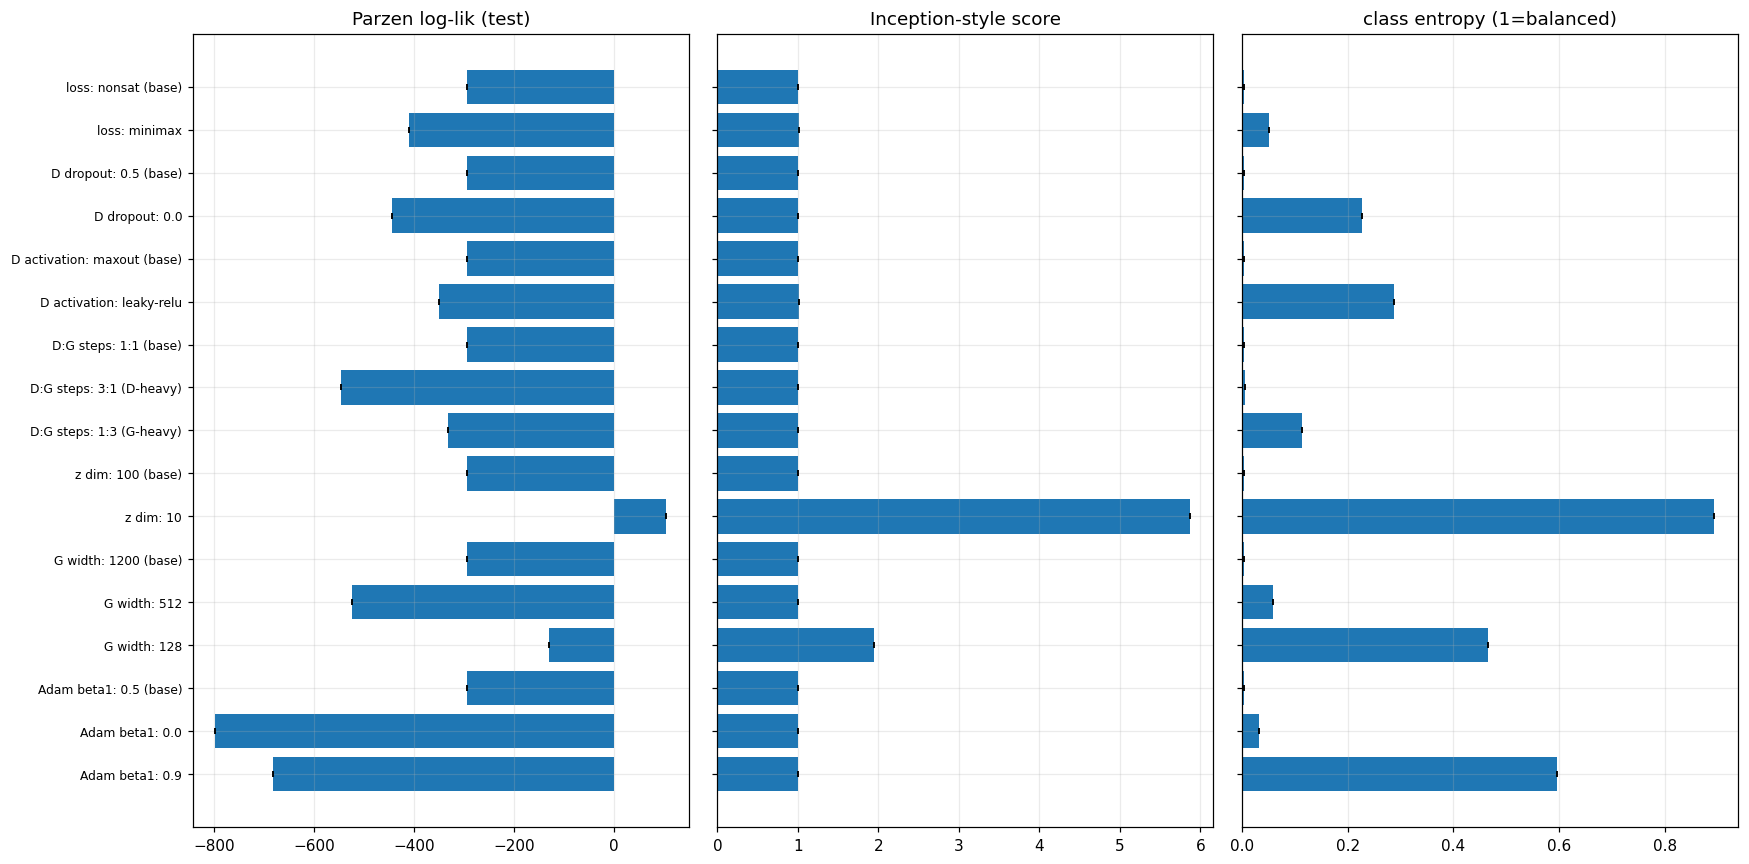

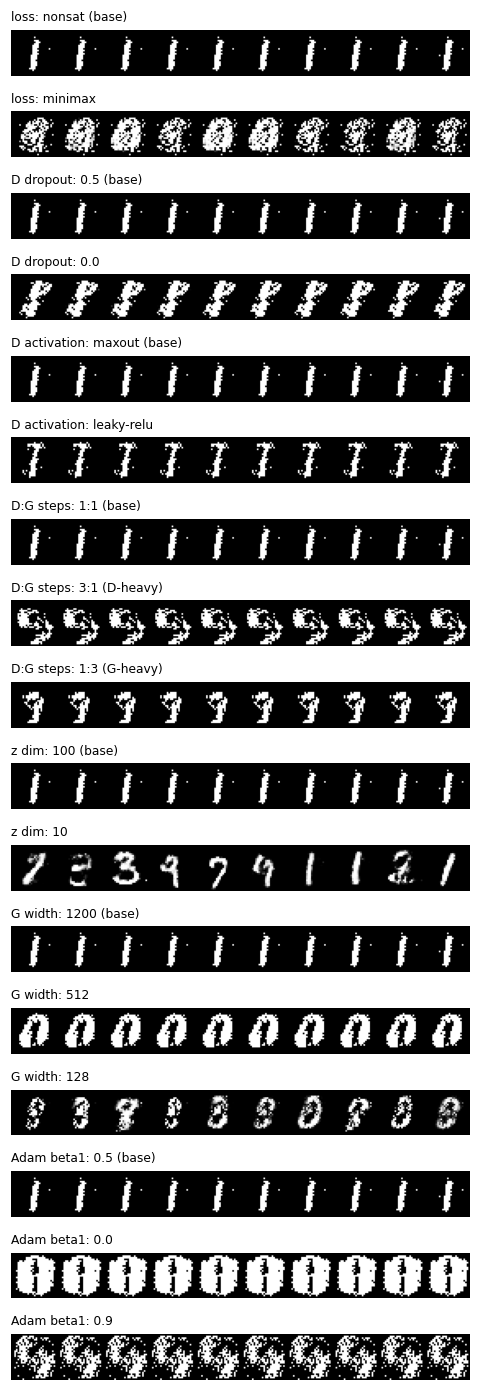

In [22]:
agg = df_mn.groupby(["factor", "option"], sort=False)[["parzen_ll", "IS", "class_entropy", "conf"]].agg(["mean", "std"])
display(agg.round(3))

lab = [f"{f}: {o}" for f, o in agg.index]
fig, axes = plt.subplots(1, 3, figsize=(16, 0.38 * len(lab) + 1.5), sharey=True)
for ax, (m, t) in zip(axes, [("parzen_ll", "Parzen log-lik (test)"), ("IS", "Inception-style score"), ("class_entropy", "class entropy (1=balanced)")]):
    ax.barh(range(len(lab)), agg[(m, "mean")], xerr=agg[(m, "std")].fillna(0), capsize=2)
    ax.set_title(t); ax.invert_yaxis()
axes[0].set_yticks(range(len(lab))); axes[0].set_yticklabels(lab, fontsize=8)
plt.tight_layout(); plt.show()

keys = list(mn_strips)
fig, axes = plt.subplots(len(keys), 1, figsize=(8, 0.75 * len(keys)))
for ax, k in zip(np.atleast_1d(axes), keys):
    show(mn_strips[k], 10, "", ax=ax); ax.set_title(f"{k[0]}: {k[1]}", fontsize=8, loc="left")
plt.tight_layout(); plt.show()

In [23]:
# Save whatever tables exist, so you can download them from the Colab file browser
for name in ["df_main", "df_abl", "df_mn", "df_table1"]:
    if name in globals():
        globals()[name].to_csv(f"{name}.csv", index=False)
        print("saved", f"{name}.csv")

saved df_main.csv
saved df_abl.csv
saved df_mn.csv
saved df_table1.csv


## 8. Deviations from the paper and what the stored outputs show

**Deviations from the original paper's setup (as in the report):**
* Adam (β₁ = 0.5) instead of SGD with momentum.
* Shorter training (20k iterations for the main MNIST run; 8k for the MNIST ablations).
* A single seed for the main MNIST run and for the whole MNIST ablation; 2–3 seeds for the toy experiments.
* The DBN, stacked CAE and deep GSN numbers in Section 6 are **quoted from the paper**, not re-trained.
* No TFD or CIFAR-10 experiments.
* The Parzen bandwidth is chosen from a 10-point log grid on [0.1, 1].

**What the stored outputs show (single run, nothing here is a claim beyond these runs):**
* *Toy data:* on `ring8` both losses cover (almost) all 8 modes; on `grid25` neither loss covers all 25 modes and the minimax / non-saturating difference is within seed-to-seed spread. A G-heavy 1:5 update ratio collapses `ring8` to 0/8 modes, matching the paper's "Helvetica scenario" warning.
* *MNIST:* both generators collapsed (Inception-style score ≈ 1, class entropy near 0) with the discriminator overpowering the generator, so the Parzen numbers are not comparable to the paper's 225 ± 2. The estimator itself behaves sensibly (KDE of 10k real images: 242.4 ± 2.1; untrained generator: −541.3).
* *MNIST ablation (preliminary, 1 seed, 8k iterations):* reducing the noise dimension to 10 or the generator width to 128 avoided the collapse in this single run (Parzen +103.9 / −131.1); this needs multiple seeds before it can be trusted.